## Задание 5: Поиск дел (todos) с определенным статусом

Выполнил: Ларюшкин Кирилл Александрович

Группа: 292605

```bash
python -m venv venv
venv\Scripts\activate
pip install requests
pip freeze > requirements.txt
```

In [3]:
import requests
import logging


logging.basicConfig(
    filename='task5.log',  # Файл куда сохранять логи
    filemode='w',  # Режим - перезаписывать файл с логами при запуске
    level=logging.DEBUG,  # Определениение уровня логирования - уровень логирования DEBUG и выше,
    format='%(asctime)s - %(levelname)s - %(message)s',  # Формат логов
    encoding='UTF-8',  # Кодировка UTF-8 , для корректного отображения кириллицы 
)


def todos(flt: bool | None = None):
    """ Функция которая получает список всех задач ToDo листа
    Имеет возможность фильтрации задач по критериям : выполненные, не выполненные
    Возвращает кол-во задач и либо полный список задач, либо список выполненных или не выполненных задач в зависимости от выбранного фильтра
    """
    
    try:
        logging.info('Обращение к API ...')
        
        url = 'https://dummyjson.com/todos'  # URL списка задач

        response = requests.get(url, timeout=10)  # GET запрос с тайм-аутом
        response.raise_for_status()  # контроль статус-кодов ответа для отравливания ошибок

        data = response.json()  # Преобзраем полученый результат в словарь

        tasks = data.get('todos', [])  # Получаем список словарей с задачами , либо пустой список

        # Сразу првоеряем есть ли задачи в списке и если нет, выводим сообещние и заканчсиваем работу функции
        if  not tasks:
            logging.info('Обращение прошло успешно. Список задач пуст')  # Логирование информации о том, что список задач пуст, обращение прошло успешно
            print('Список задач пуст. Создайте задачу')  # Сообщение пользователю
            return None  # Заканчиваем работу функции

        # Проверяем фильтр, если значение False, то отображаем только не успешно завершенные задачи и их кол-во
        if flt is False:
            logging.info('Обращение прошло успешно. Опеределен фильтр по задачам - Не выполененные')  # Логирование информации о том, что есть фильтр и обращение прошло успешно
            logging.info('Обработка данных ...')  # Логирование информации о том, что происходит обработка данных согласно фильтру
            
            uncomplete_tasks = [task for task in tasks if not task['completed']]  # Списковое включение, в котором цилком формируем список состоящий только из не выполненных задач
            
            lengh_uncomplete_tasks = len(uncomplete_tasks)  # сохраняем в переменную кол-во задач, что бы постоянно не повторять подсчет
            
            print(f'У вас {lengh_uncomplete_tasks} не выполненных задач')  # Сообщение о кол-ве не выполненных задач
            
            # Цикл в которм выводим информацию о каждой не выполненном задаче
            for task in uncomplete_tasks:
                print(f'№{task["id"]}. Задача: {task["todo"]}. Статус: Не завершенно')  # Сообщение с информацией по задаче

            logging.info(f'Обработка данных успешно завершена. Найдено {lengh_uncomplete_tasks} не выполненные задачи')  # Логируем информацию о обработке данных и кол-ве задач
            logging.info('Список не выполненных задач успешно выведен на экран')  # Логируем результат функции 
            
                
        # Если значение True, то отображаем только успешно завершенные задачи и их кол-во    
        elif flt:
            logging.info('Обращение прошло успешно. Опеределен фильтр по задачам - выполененные')
            logging.info('Обработка данных ...')
            
            complete_tasks = [task for task in tasks if  task['completed']] # Списковое включение, в котором цилком формируем список состоящий только из выполненных задач
            lengh_complete_tasks = len(complete_tasks)  # сохраняем в переменную кол-во задач, что бы постоянно не повторять подсчет
            
            print(f'У вас {lengh_complete_tasks} выполненных задач')  # Сообщение о кол-ве выполненных задач

            # Цикл в которм выводим информацию о каждой выполненной задаче
            for task in complete_tasks:
                print(f'№{task["id"]}. Задача: {task["todo"]}. Статус: Завершено')  # Сообщение с информацией по задачее

            logging.info(f'Обработка данных успешно завершена. Найдено {lengh_complete_tasks} выполненные задачи')  # Логируем информацию о обработке данных и кол-ве задач
            logging.info('Список выполненных задач успешно выведен на экран')  # Логируем результат функции 
                
        # Если фильтр не установлен, то выводим весь список задач
        else:
            logging.info('Обращение прошло успешно. Фильтр отсутствует')
            logging.info('Обработка данных ...')
            
            lenght_tasks = len(tasks)  # сохраняем в переменную кол-во задач, что бы постоянно не повторять подсчет
            
            print(f'У вас {lenght_tasks} задач/и')  # Сообщение с общем кол-вом задач
            print('Список всех задач: ')  # Сообещние заголовок
            
            # Цикл в котором выодим информацию по каждой задаче
            for task in tasks:
                print(f'№{task["id"]}. Задача: {task["todo"]}. Статус: {"Завершено" if task["completed"] else "Не завершенно"}')  # Сообщение с информацией по каждой задаче
                
            logging.info(f'Обработка данных успешно завершена. Найдено {lenght_tasks} задачи')  # Логируем информацию о обработке данных и кол-ве задач
            logging.info('Список задач успешно выведен на экран')  # Логируем результат функции 
        

        
    except requests.exceptions.HTTPError as e: # Обрабатывает случай, когда запрос был успешно отправлено сервер его обработал, но вернул статус-код указывающий на ошибку
        logging.error(f'Обращение к серверу прошло успешно, сервер его обработал но вернул ошибку : {e}')  # Логирует ошибку
        print(f'Обращение к серверу прошло успешно, сервер его обработал но вернул ошибку : {e}')  # Вовзращаем сообщение с ошибкой

    except requests.exceptions.RequestException as e:  # Обрабатывает ошибки при обращении к API
        logging.error(f'Произошла ошибка:{e}')  # Логирует ошибку
        print(f'Произошла ошибка: {e}')  # Вовзращаем сообщение с ошибкой
        
    except requests.exceptions.JSONDecodeError as e:  # Обрабатывает ошибки при преобразовании JSON
        logging.error(f'Ошибка декодирования JSON: {e}')  # Логирует ошибку
        print(f'Ошибка обработки JSON: {e}')  # Вовзращаем сообщение с ошибкой

    except (TypeError, ValueError, KeyError) as e:  # Обрабатывает ошибки при обработки данных
        logging.error(f'Ошибка типа данных:{e}')  # Логирует ошибку
        print(f'Ошибка типа данных: {e}') # Вовзращаем сообщение с ошибкой


if __name__=='__main__':   # Запускать можно только из главного файла, импортировать нельзя
    logging.info('Старт работы программы')
    
    while True:
        user_input = input('Выберите какие задачи хотите увидеть:\n'
                '1) Все задачи\n'
                '2) Выполненные задачи\n'
                '3) Не выполненные задачи\n'
                'Введите "q" что бы выйти\n'
            ).strip()
        
        # Выход из программы
        if user_input=="q":
            logging.info('Работа программы завершена')
            print('Работа программы завершена')  # Сообщение о завершении работы программы
            break  # Завершении работы программы
            
        # Если пользователь выбрал пункт 1-Отобразить все задачи, то запускаем функцию tasks с дефолтным параметром flt=None
        elif user_input=='1':
            logging.info('Пользователь выбрал пункт 1- Отобразить все задачи')
            todos()
            
        # Если пользователь выбрал пункт 2-Отобразить только выполненные задачи, то запускаем функцию tasks c параметром flt=True
        elif user_input=='2':
            logging.info('Пользователь выбрал пункт 2- Отобразить выполненные задачи')
            todos(flt=True)

        # Если пользователь выбрал пункт 3-Отобразить только не выполненные задачи, то запускаем функцию tasks c параметром flt=False
        elif user_input=='3':
            logging.info('Пользователь выбрал пункт 3- Отобразить не выполненные задачи')
            todos(flt=False)
            
        # Если пользователь ввел не верное значение, то отображаем сообщение с возможными функциями программы
        else:
            logging.warning(f'Некорректный ввод. Пользователь ввел - {user_input}')
            print('Пожалуйста, выберите пункт 1,2,3 введя целое число, либо введите "q" что бы выйти')
    
        

Выберите какие задачи хотите увидеть:
1) Все задачи
2) Выполненные задачи
3) Не выполненные задачи
Введите "q" что бы выйти
 1


У вас 30 задач/и
Список всех задач: 
№1. Задача: Do something nice for someone you care about. Статус: Не завершенно
№2. Задача: Memorize a poem. Статус: Завершено
№3. Задача: Watch a classic movie. Статус: Завершено
№4. Задача: Watch a documentary. Статус: Не завершенно
№5. Задача: Invest in cryptocurrency. Статус: Не завершенно
№6. Задача: Contribute code or a monetary donation to an open-source software project. Статус: Не завершенно
№7. Задача: Solve a Rubik's cube. Статус: Завершено
№8. Задача: Bake pastries for yourself and neighbor. Статус: Завершено
№9. Задача: Go see a Broadway production. Статус: Не завершенно
№10. Задача: Write a thank you letter to an influential person in your life. Статус: Завершено
№11. Задача: Invite some friends over for a game night. Статус: Не завершенно
№12. Задача: Have a football scrimmage with some friends. Статус: Не завершенно
№13. Задача: Text a friend you haven't talked to in a long time. Статус: Завершено
№14. Задача: Organize pantry. Статус

Выберите какие задачи хотите увидеть:
1) Все задачи
2) Выполненные задачи
3) Не выполненные задачи
Введите "q" что бы выйти
                                                                   2                                       


У вас 15 выполненных задач
№2. Задача: Memorize a poem. Статус: Завершено
№3. Задача: Watch a classic movie. Статус: Завершено
№7. Задача: Solve a Rubik's cube. Статус: Завершено
№8. Задача: Bake pastries for yourself and neighbor. Статус: Завершено
№10. Задача: Write a thank you letter to an influential person in your life. Статус: Завершено
№13. Задача: Text a friend you haven't talked to in a long time. Статус: Завершено
№15. Задача: Buy a new house decoration. Статус: Завершено
№16. Задача: Plan a vacation you've always wanted to take. Статус: Завершено
№18. Задача: Draw and color a Mandala. Статус: Завершено
№19. Задача: Create a cookbook with favorite recipes. Статус: Завершено
№22. Задача: Take a hike at a local park. Статус: Завершено
№23. Задача: Take a class at local community center that interests you. Статус: Завершено
№24. Задача: Research a topic interested in. Статус: Завершено
№29. Задача: Have a photo session with some friends. Статус: Завершено
№30. Задача: Go to the 

Выберите какие задачи хотите увидеть:
1) Все задачи
2) Выполненные задачи
3) Не выполненные задачи
Введите "q" что бы выйти
                                                                            3                              


У вас 15 не выполненных задач
№1. Задача: Do something nice for someone you care about. Статус: Не завершенно
№4. Задача: Watch a documentary. Статус: Не завершенно
№5. Задача: Invest in cryptocurrency. Статус: Не завершенно
№6. Задача: Contribute code or a monetary donation to an open-source software project. Статус: Не завершенно
№9. Задача: Go see a Broadway production. Статус: Не завершенно
№11. Задача: Invite some friends over for a game night. Статус: Не завершенно
№12. Задача: Have a football scrimmage with some friends. Статус: Не завершенно
№14. Задача: Organize pantry. Статус: Не завершенно
№17. Задача: Clean out car. Статус: Не завершенно
№20. Задача: Bake a pie with some friends. Статус: Не завершенно
№21. Задача: Create a compost pile. Статус: Не завершенно
№25. Задача: Plan a trip to another country. Статус: Не завершенно
№26. Задача: Improve touch typing. Статус: Не завершенно
№27. Задача: Learn Express.js. Статус: Не завершенно
№28. Задача: Learn calligraphy. Статус: Не

... (2 outputs left out)

Выберите какие задачи хотите увидеть:
1) Все задачи
2) Выполненные задачи
3) Не выполненные задачи
Введите "q" что бы выйти
 f


Пожалуйста, выберите пункт 1,2,3 введя целое число, либо введите "q" что бы выйти


Выберите какие задачи хотите увидеть:
1) Все задачи
2) Выполненные задачи
3) Не выполненные задачи
Введите "q" что бы выйти
 q


Работа программы завершена


```bash
deactivate
```

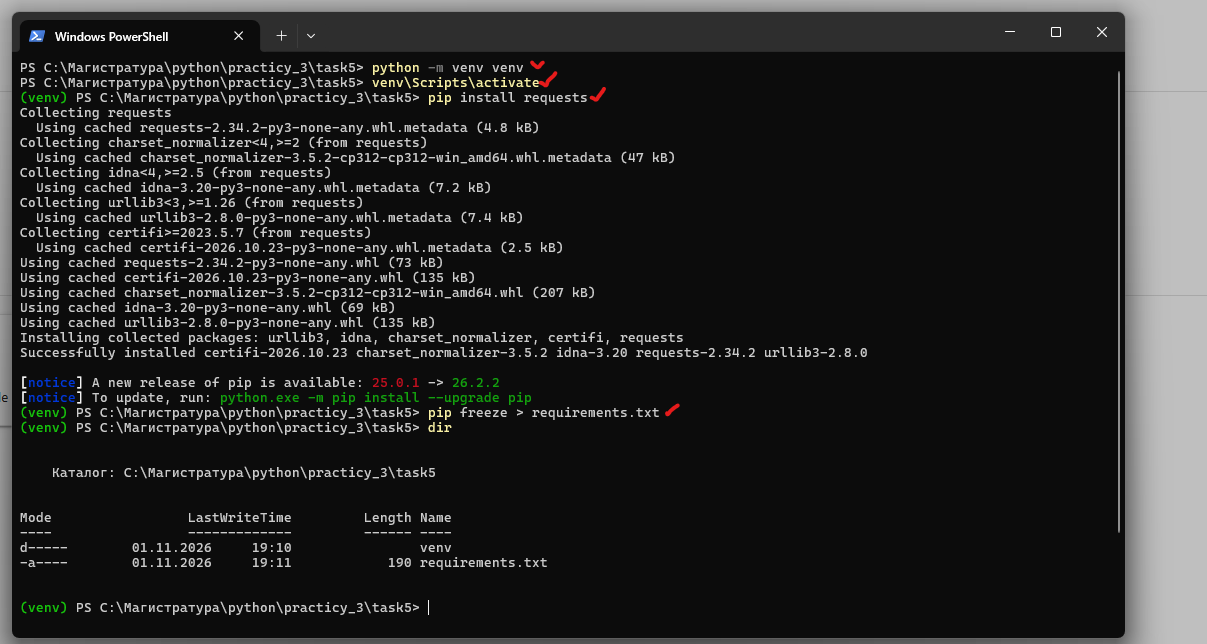

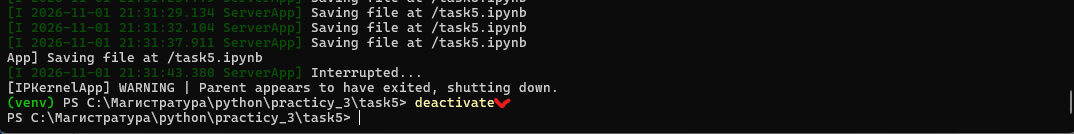